# Quantum electronics — course recap

### Subject: Quantum electronics

A public map of the Sapienza *Elettronica quantistica* course: light as wave
and photon, two-level atoms, laser rate equations, semiconductor and fiber
lasers, photonic crystals, surface plasmons, quantum dots — and how they
connect to qubits.

These are **original notes and demos**. Course PDFs and lecture recordings in
local `data/` stay unpublished (copyright).

Companion notebooks in this folder:
- `01_rabi_oscillations.ipynb` — driven two-level Schrödinger equation
- `02_semiconductor_states_and_dos.ipynb` — wells, DOS, Fermi–Dirac, 2D

## Course spine

The course is the hardware layer of quantum information: how light, atoms and
solids produce coherent photons and confined electrons — the physical objects
we later treat as qubits.

| Theme | What to take away |
|---|---|
| Optics refresh | Maxwell waves, the photon, refraction / interfaces |
| Atomic transitions | Spontaneous vs stimulated emission, two-level Rabi |
| Laser rate equations | 3-level vs 4-level, threshold, photon build-up |
| Semiconductor lasers | Bands, doping, DOS, Fermi occupation, diodes |
| Fiber lasers | Rare-earth doped fiber, cavity vs MOPA, pump diodes |
| Photonic crystals | Bloch photons, band gaps, defects, PC fibers |
| Plasmonics | Surface plasmon polaritons, sub-wavelength confinement |
| Quantum dots | 0D confinement and discrete optical transitions |
| Ultrafast / pulses | How a laser leaves CW and becomes a clock |

Recorded lectures in the local (unpublished) archive: 13 sessions from
2026-05-19 to 2026-09-15.

## 0. Setup

In [1]:
import sys
from pathlib import Path

_here = Path.cwd().resolve()
for candidate in (_here, _here.parent, _here.parent.parent):
    if (candidate / "_common").is_dir():
        sys.path.insert(0, str(candidate))
        break

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

from _common import PAULI_X, PAULI_Z, ket0

print("Setup ready.")

Setup ready.


## 1. Light: why the laser exists

Maxwell already gives waves; Einstein's photon gives packets of energy $\hbar\omega$.
Engineering optics exploded only when a coherent optical oscillator appeared —
the **laser**. Everything below is the physics of that oscillator and of the
nanostructures that guide, confine or generate its light.

## 2. Two-level atom and Rabi flopping

A qubit is a two-level system. A near-resonant drive

$$
H = \frac{\Delta}{2} Z + \frac{\Omega}{2} X
$$

makes the excited population oscillate at the effective Rabi frequency
$\sqrt{\Omega^2+\Delta^2}$. Starting from $|0\rangle$:

$$
P_e(t) = \left(\frac{\Omega}{\Omega_\mathrm{eff}}\right)^2 \sin^2\!\left(\frac{\Omega_\mathrm{eff}\, t}{2}\right).
$$

On resonance the inversion is complete; off resonance it is not. A $\pi$-pulse
is the hardware origin of an $X$ gate. The full time integration lives in
`01_rabi_oscillations.ipynb`.

on resonance $\Delta=0$: analytic = numeric? True
off resonance $\Delta=\Omega$: analytic = numeric? True


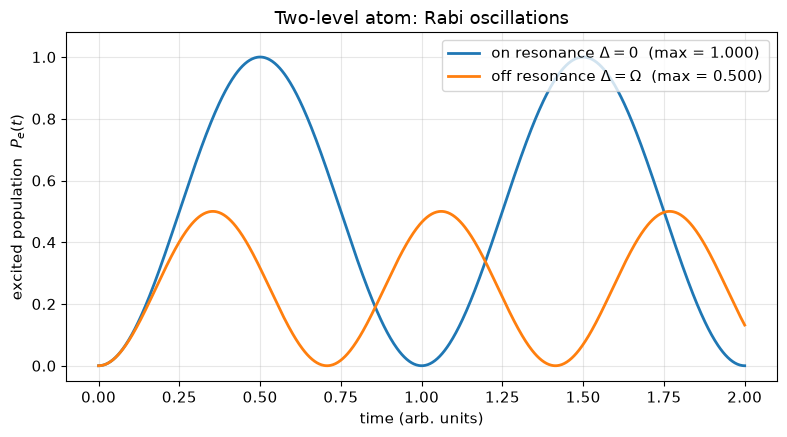

In [2]:
def rabi_population(omega, delta, t):
    omega_eff = np.sqrt(omega**2 + delta**2)
    amp = 0.0 if omega_eff == 0 else (omega / omega_eff) ** 2
    return amp * np.sin(0.5 * omega_eff * t) ** 2

omega = 2 * np.pi
t = np.linspace(0.0, 2.0, 800)

fig, ax = plt.subplots()
for delta, label in [(0.0, r"on resonance $\Delta=0$"), (omega, r"off resonance $\Delta=\Omega$")]:
    pop = rabi_population(omega, delta, t)
    ax.plot(t, pop, lw=2, label=f"{label}  (max = {pop.max():.3f})")

    H = 0.5 * delta * PAULI_Z + 0.5 * omega * PAULI_X
    evals, evecs = np.linalg.eigh(H)
    psi0 = ket0.reshape(2)
    t_check = np.array([0.25, 0.5, 1.0])
    analytic = rabi_population(omega, delta, t_check)
    numeric = []
    for ti in t_check:
        u = evecs @ np.diag(np.exp(-1j * evals * ti)) @ evecs.conj().T
        numeric.append(abs((u @ psi0)[1]) ** 2)
    print(f"{label}: analytic = numeric? {np.allclose(analytic, numeric, atol=1e-10)}")

ax.set_xlabel("time (arb. units)")
ax.set_ylabel(r"excited population  $P_e(t)$")
ax.set_title("Two-level atom: Rabi oscillations")
ax.set_ylim(-0.05, 1.08)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Laser rate equations: threshold is a balance

A **4-level** laser needs less pump than a **3-level** one because the lower
laser level empties quickly, so inversion is cheaper. Threshold is the point
where stimulated gain exactly cancels cavity loss.

Dimensionless model ($n$ = inversion / threshold, $q$ = cavity photons):

$$
\dot n = R - \frac{n}{\tau_\mathrm{sp}} - n q, \qquad
\dot q = \frac{(n-1)q}{\tau_\mathrm{ph}} + \beta\,\frac{n}{\tau_\mathrm{sp}}.
$$

Below threshold the photon number stays near the spontaneous seed; above it
the field switches on, often with relaxation oscillations.

pump=0.7:  n(∞)=0.700   q(∞)=0.000   lasing=no (below threshold)
pump=1.6:  n(∞)=1.000   q(∞)=0.600   lasing=yes


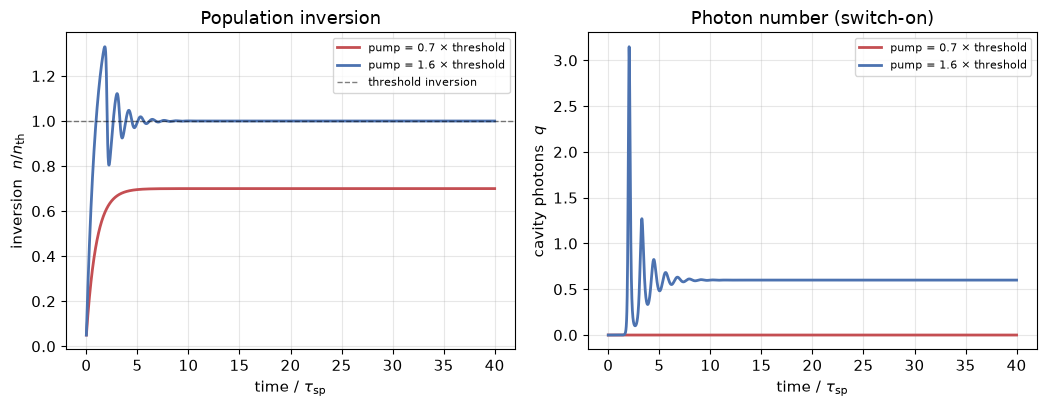

In [3]:
def laser_rate_rhs(y, pump, tau_sp, tau_ph, beta):
    n, q = y
    dn = pump - n / tau_sp - n * q
    dq = (n - 1.0) * q / tau_ph + beta * n / tau_sp
    return np.array([dn, dq])

def rk4(fun, y0, t, **kwargs):
    y = np.empty((len(t), y0.size), dtype=float)
    y[0] = y0
    for i in range(len(t) - 1):
        dt = t[i + 1] - t[i]
        k1 = fun(y[i], **kwargs)
        k2 = fun(y[i] + 0.5 * dt * k1, **kwargs)
        k3 = fun(y[i] + 0.5 * dt * k2, **kwargs)
        k4 = fun(y[i] + dt * k3, **kwargs)
        y[i + 1] = y[i] + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return y

tau_sp, tau_ph, beta = 1.0, 0.02, 1e-4
t = np.linspace(0.0, 40.0, 4000)
y0 = np.array([0.05, 1e-6])

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.2), sharex=True)
for pump, color in [(0.7, "#C44E52"), (1.6, "#4C72B0")]:
    traj = rk4(laser_rate_rhs, y0, t, pump=pump, tau_sp=tau_sp, tau_ph=tau_ph, beta=beta)
    n, q = traj[:, 0], traj[:, 1]
    label = f"pump = {pump:.1f} × threshold"
    axes[0].plot(t, n, color=color, lw=2, label=label)
    axes[1].plot(t, q, color=color, lw=2, label=label)
    print(f"pump={pump:.1f}:  n(∞)={n[-1]:.3f}   q(∞)={q[-1]:.3f}   "
          f"lasing={'yes' if q[-1] > 0.05 else 'no (below threshold)'}")

axes[0].axhline(1.0, color="k", ls="--", lw=1, alpha=0.5, label="threshold inversion")
axes[0].set_ylabel(r"inversion  $n / n_\mathrm{th}$")
axes[0].set_title("Population inversion")
axes[1].set_ylabel("cavity photons  $q$")
axes[1].set_title("Photon number (switch-on)")
for ax in axes:
    ax.set_xlabel(r"time / $\tau_\mathrm{sp}$")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Semiconductor laser: inversion in bands

In a diode the "levels" are **bands**. Optical gain requires a quasi-Fermi
separation larger than the gap,

$$
\mu_c - \mu_v > E_g,
$$

so that conduction states at the photon energy are more occupied than the
valence states. Density of states tells us how many of those states exist;
Fermi–Dirac tells us how they are filled. Quantum wells flatten the DOS and
concentrate the gain — see `02_semiconductor_states_and_dos.ipynb`.

thermal equilibrium (no inversion):  μ_c-μ_v = 0.40 eV   gap = 1.42 eV   gain? False
pumped: quasi-Fermi inversion:  μ_c-μ_v = 1.50 eV   gap = 1.42 eV   gain? True


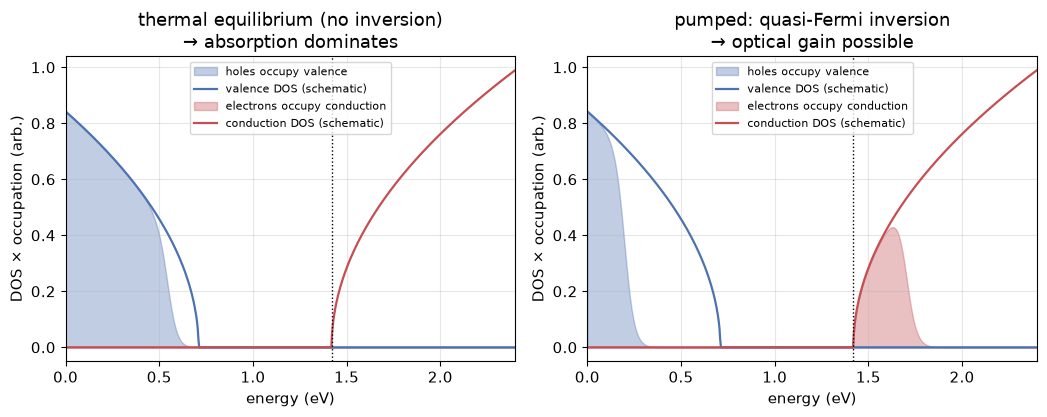

In [4]:
def fermi_dirac(E, mu, kT):
    return 1.0 / (1.0 + np.exp(np.clip((E - mu) / kT, -60.0, 60.0)))

Eg, kT = 1.42, 0.026  # GaAs-like gap (eV), room temperature
E = np.linspace(0.0, 2.4, 600)
dos_v = np.sqrt(np.clip(Eg / 2 - E, 0, None))
dos_c = np.sqrt(np.clip(E - Eg, 0, None))

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.3))
for ax, (mu_c, mu_v, title) in [
    (axes[0], (0.95, 0.55, "thermal equilibrium (no inversion)")),
    (axes[1], (1.70, 0.20, "pumped: quasi-Fermi inversion")),
]:
    fc, fv = fermi_dirac(E, mu_c, kT), fermi_dirac(E, mu_v, kT)
    ax.fill_between(E, 0, dos_v * fv, color="#4C72B0", alpha=0.35, label="holes occupy valence")
    ax.plot(E, dos_v, color="#4C72B0", lw=1.6, label="valence DOS (schematic)")
    ax.fill_between(E, 0, dos_c * fc, color="#C44E52", alpha=0.35, label="electrons occupy conduction")
    ax.plot(E, dos_c, color="#C44E52", lw=1.6, label="conduction DOS (schematic)")
    ax.axvline(Eg, color="k", ls=":", lw=1)
    inversion = (mu_c - mu_v) > Eg
    ax.set_title(title + ("\n→ optical gain possible" if inversion else "\n→ absorption dominates"))
    ax.set_xlabel("energy (eV)")
    ax.set_ylabel("DOS × occupation (arb.)")
    ax.set_xlim(0, 2.4)
    ax.legend(fontsize=8)
    print(f"{title}:  μ_c-μ_v = {mu_c - mu_v:.2f} eV   gap = {Eg:.2f} eV   gain? {inversion}")

plt.tight_layout()
plt.show()

## 5. Fiber lasers: a doped waveguide as the gain medium

Replace the bulk crystal with a glass fiber doped with rare-earth ions
(Yb, Er, Tm). Pump diodes at 915/976 nm invert the ions; emission sits near
1.0 μm (Yb) or 1.5 μm (Er).

Two architectures dominate:

- a **standing-wave cavity** (light travels both ways through the fiber);
- a **MOPA** (a weak seeder amplified in one direction).

The fiber is both the gain medium and the waveguide.

## 6. Photonic crystals: Bragg for photons

A periodic dielectric does to photons what the atomic lattice does to
electrons: **Bloch modes** and forbidden bands. For a 1D bilayer stack at
normal incidence ($c=1$):

$$
\cos(K\Lambda) = \cos(k_1 d_1)\cos(k_2 d_2)
- \frac{n_1^2+n_2^2}{2 n_1 n_2}\,\sin(k_1 d_1)\sin(k_2 d_2).
$$

Allowed bands: $|\cos(K\Lambda)|\le 1$. In 2D/3D, intentional defects make
waveguides and high-Q cavities; a periodic cladding makes a photonic-crystal fiber.

1D stack n=(1.5, 3.4): about 31% of the plotted spectrum sits in a gap


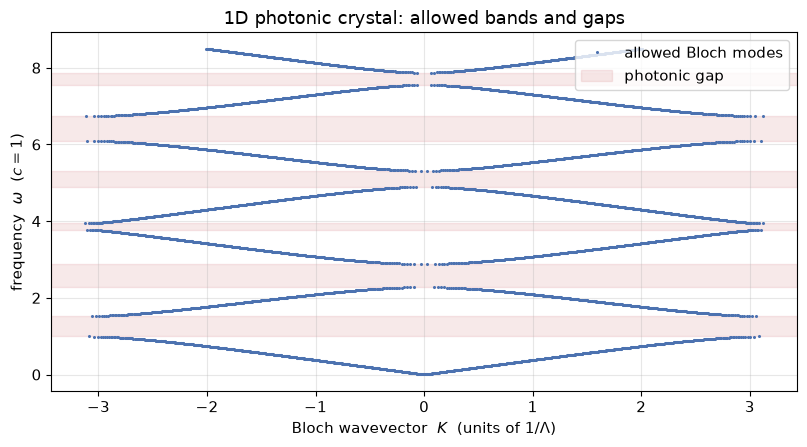

In [5]:
def bilayer_bloch_cos(omega, n1, n2, d1, d2):
    k1, k2 = n1 * omega, n2 * omega
    mismatch = (n1 / n2 + n2 / n1) / 2.0
    return np.cos(k1 * d1) * np.cos(k2 * d2) - mismatch * np.sin(k1 * d1) * np.sin(k2 * d2)

n1, n2, d1, d2 = 1.5, 3.4, 0.5, 0.5
period = d1 + d2
omega = np.linspace(1e-3, 8.5, 4000)
cosk = bilayer_bloch_cos(omega, n1, n2, d1, d2)
allowed = np.abs(cosk) <= 1.0

K = np.full_like(omega, np.nan)
K[allowed] = np.arccos(np.clip(cosk[allowed], -1.0, 1.0)) / period

fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.plot(K, omega, "o", ms=1.2, color="#4C72B0", label="allowed Bloch modes")
ax.plot(-K, omega, "o", ms=1.2, color="#4C72B0")

gap_mask = ~allowed
in_gap, start, first_gap = False, 0, True
for i, g in enumerate(gap_mask):
    if g and not in_gap:
        start, in_gap = i, True
    elif not g and in_gap:
        ax.axhspan(omega[start], omega[i], color="#C44E52", alpha=0.12,
                   label="photonic gap" if first_gap else None)
        first_gap, in_gap = False, False

print(f"1D stack n=({n1}, {n2}): about {int(np.mean(gap_mask)*100)}% of the plotted spectrum sits in a gap")
ax.set_xlabel(r"Bloch wavevector  $K$  (units of $1/\Lambda$)")
ax.set_ylabel(r"frequency  $\omega$  ($c=1$)")
ax.set_title("1D photonic crystal: allowed bands and gaps")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 7. Surface plasmons: light glued to a metal

At a metal/dielectric interface a TM surface wave — the **SPP** — binds to
the free charges. With a lossless Drude metal $\varepsilon_m = 1-\omega_p^2/\omega^2$:

$$
k_\mathrm{SPP}(\omega) = \frac{\omega}{c}\sqrt{\frac{\varepsilon_m\varepsilon_d}{\varepsilon_m+\varepsilon_d}},
\qquad \text{bound only if }\ \varepsilon_m+\varepsilon_d<0.
$$

The dispersion lies **beyond the light line**, so the mode is evanescent on
both sides and can be squeezed below the diffraction limit. Coupling in needs
extra momentum (grating, prism, near field).

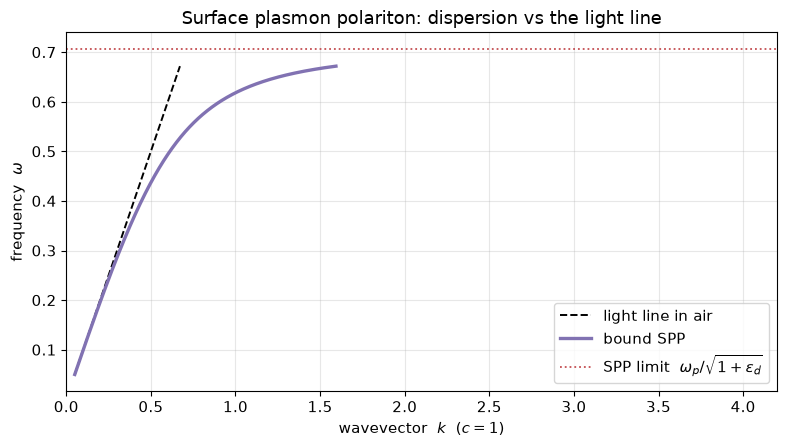

SPP asymptotic frequency / ω_p = 0.707  (air, lossless Drude)
The SPP sits to the right of the light line: extra momentum is needed to couple in.


In [6]:
def spp_wavevector(omega, omega_p, eps_d):
    eps_m = 1.0 - (omega_p / omega) ** 2
    disc = eps_m * eps_d / (eps_m + eps_d)
    k = omega * np.sqrt(disc + 0j)
    bound = (eps_m + eps_d) < 0
    out = np.full_like(omega, np.nan, dtype=float)
    out[bound] = np.real(k[bound])
    return out

omega_p, eps_d = 1.0, 1.0
omega_spp = omega_p / np.sqrt(1 + eps_d)
omega = np.linspace(0.05, 0.95 * omega_spp, 800)
k_spp = spp_wavevector(omega, omega_p, eps_d)

fig, ax = plt.subplots(figsize=(8.0, 4.6))
ax.plot(omega, omega, "k--", lw=1.4, label="light line in air")
ax.plot(k_spp, omega, color="#8172B2", lw=2.4, label="bound SPP")
ax.axhline(omega_spp, color="#C44E52", ls=":", lw=1.3,
           label=r"SPP limit  $\omega_p/\sqrt{1+\varepsilon_d}$")
ax.set_xlabel(r"wavevector  $k$  ($c=1$)")
ax.set_ylabel(r"frequency  $\omega$")
ax.set_title("Surface plasmon polariton: dispersion vs the light line")
ax.set_xlim(0, 4.2)
ax.legend()
plt.tight_layout()
plt.show()

print(f"SPP asymptotic frequency / ω_p = {omega_spp:.3f}  (air, lossless Drude)")
print("The SPP sits to the right of the light line: extra momentum is needed to couple in.")

## 8. Quantum dots: artificial atoms

Confining an electron in all three directions discretizes the spectrum. A cube
of side $L$ is the particle-in-a-box limit:

$$
E_{n_x n_y n_z} = \frac{\hbar^2\pi^2}{2m^* L^2}\,(n_x^2+n_y^2+n_z^2), \qquad n_i=1,2,\dots
$$

Permutations of $(n_x,n_y,n_z)$ produce degeneracies. Real dots add Coulomb
charging and selection rules; the idea is the same: **size tunes the color**.

Cube L=8 nm, m*=0.067 m_e: ground state E_111 = 263.1 meV
First levels (meV, degeneracy):
    263.1   g=1
    526.2   g=3
    789.2   g=3
    964.6   g=3
   1052.3   g=1
   1227.7   g=6


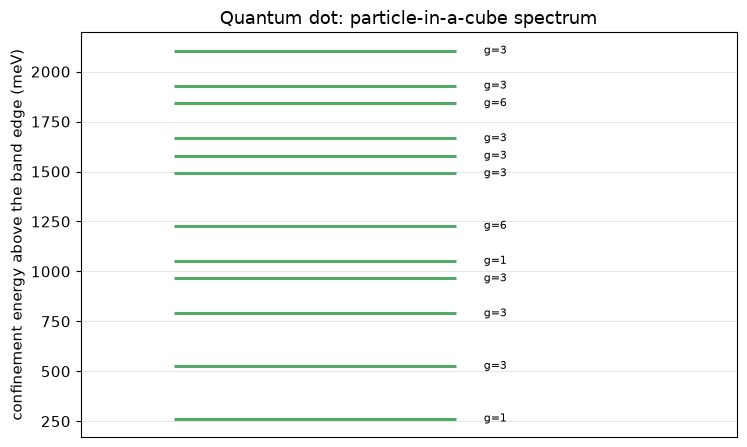

In [7]:
hbar, m_e, qe = 1.054571817e-34, 9.1093837e-31, 1.602176634e-19
mstar, L = 0.067 * m_e, 8e-9  # GaAs-like cube, 8 nm
pre = (hbar**2 * np.pi**2) / (2 * mstar * L**2) / qe * 1e3  # meV

unique = {}
for nx in range(1, 5):
    for ny in range(1, 5):
        for nz in range(1, 5):
            e = round(pre * (nx**2 + ny**2 + nz**2), 6)
            unique[e] = unique.get(e, 0) + 1

energies = np.array(sorted(unique))
degeneracy = np.array([unique[e] for e in energies])
print(f"Cube L=8 nm, m*=0.067 m_e: ground state E_111 = {energies[0]:.1f} meV")
print("First levels (meV, degeneracy):")
for e, g in zip(energies[:6], degeneracy[:6]):
    print(f"  {e:7.1f}   g={g}")

fig, ax = plt.subplots(figsize=(7.6, 4.6))
for e, g in zip(energies[:12], degeneracy[:12]):
    ax.hlines(e, 0.2, 0.8, colors="#55A868", lw=2.2)
    ax.text(0.86, e, f"g={g}", va="center", fontsize=8)
ax.set_xlim(0, 1.4)
ax.set_xticks([])
ax.set_ylabel("confinement energy above the band edge (meV)")
ax.set_title("Quantum dot: particle-in-a-cube spectrum")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. From this course to a qubit

| Course object | Qubit / quantum-info reading |
|---|---|
| Two-level atom + $\pi$ pulse | $X$ / $\sqrt{X}$ gates (notebook 01) |
| Cavity + stimulated emission | A coherent photon bus |
| Quantum well / dot | Discrete charged or excitonic qubits |
| Photonic crystal / SPP waveguide | On-chip routing of those photons |
| Semiconductor / fiber laser | The classical pump that still runs the lab |

## What to remember

- A laser is **inversion + stimulated emission + a cavity** that stores the mode.
- 4-level pumping reaches threshold with less power than 3-level pumping.
- In semiconductors, inversion is a statement about **quasi-Fermi levels vs the gap**.
- Periodicity opens gaps for photons; a metal/dielectric interface binds an SPP.
- 0D confinement (a dot) is the same Schrödinger problem as a well, in 3 axes.
- Rabi flopping is how a classical field writes a gate on a two-level qubit.

### Next steps
- Add $T_1/T_2$ decay to notebook 01 (Lindblad) and watch Rabi contrast die.
- Turn the rate-equation demo into a pump-vs-output $L$–$I$ curve.
- Compute Bragg reflectivity of a finite stack (transfer matrix).
- Compare 3D / 2D / 0D DOS on one plot (extend notebook 02).